In [ ]:
import sys
if "../" not in sys.path:
    sys.path.append("../")
    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

import scipy as sp
import os
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
import findiff as fd

In [2]:
#### SYSTEM ####

dirname = "/Users/aaronphilip/Senior Thesis/barrier-distribution-sample/16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0

### Fitting Wong formula to Morton 1999 via $\chi^2$ regression

We will consider experiments using these parameters

Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


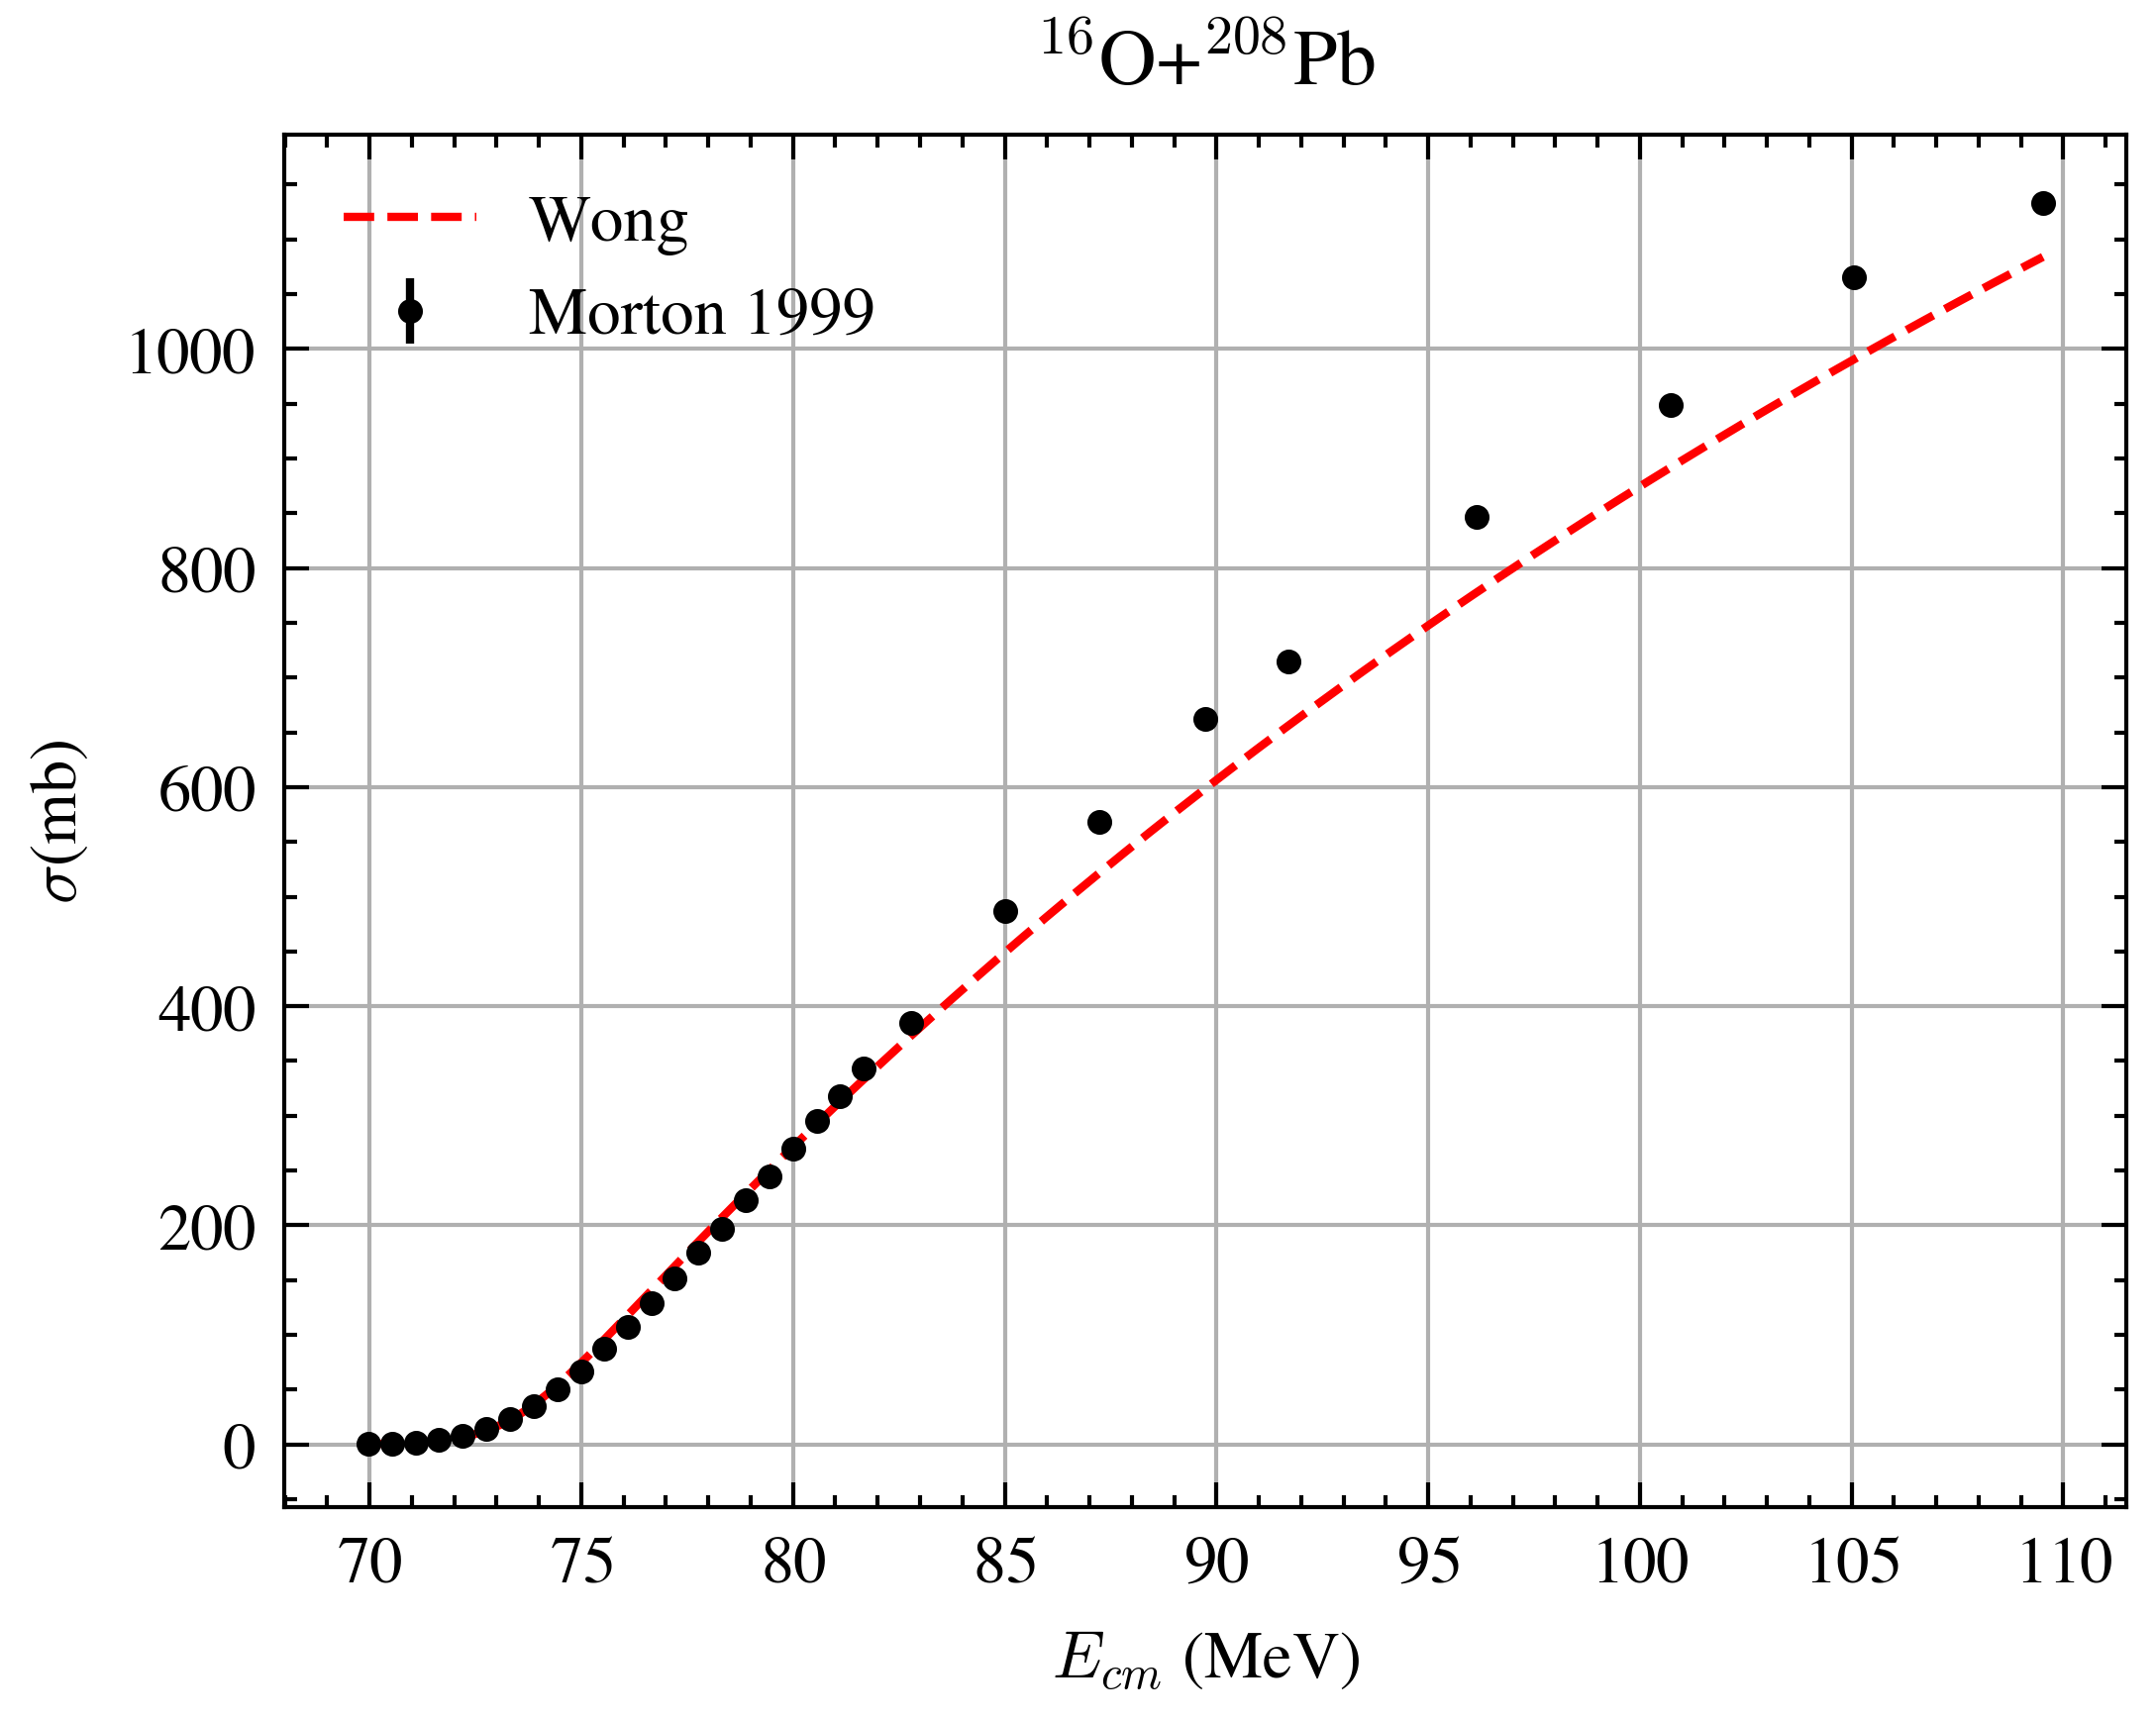

In [3]:

E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()


# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(4,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong')
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

### Fitted to Dasgupta Data without $\delta \sigma$

Best-fit parameters:
  E0    = 73.3846 ± 0.1716
  R0    = 10.2260 ± 0.0882
  hbarw = 4.8410 ± 1.3627


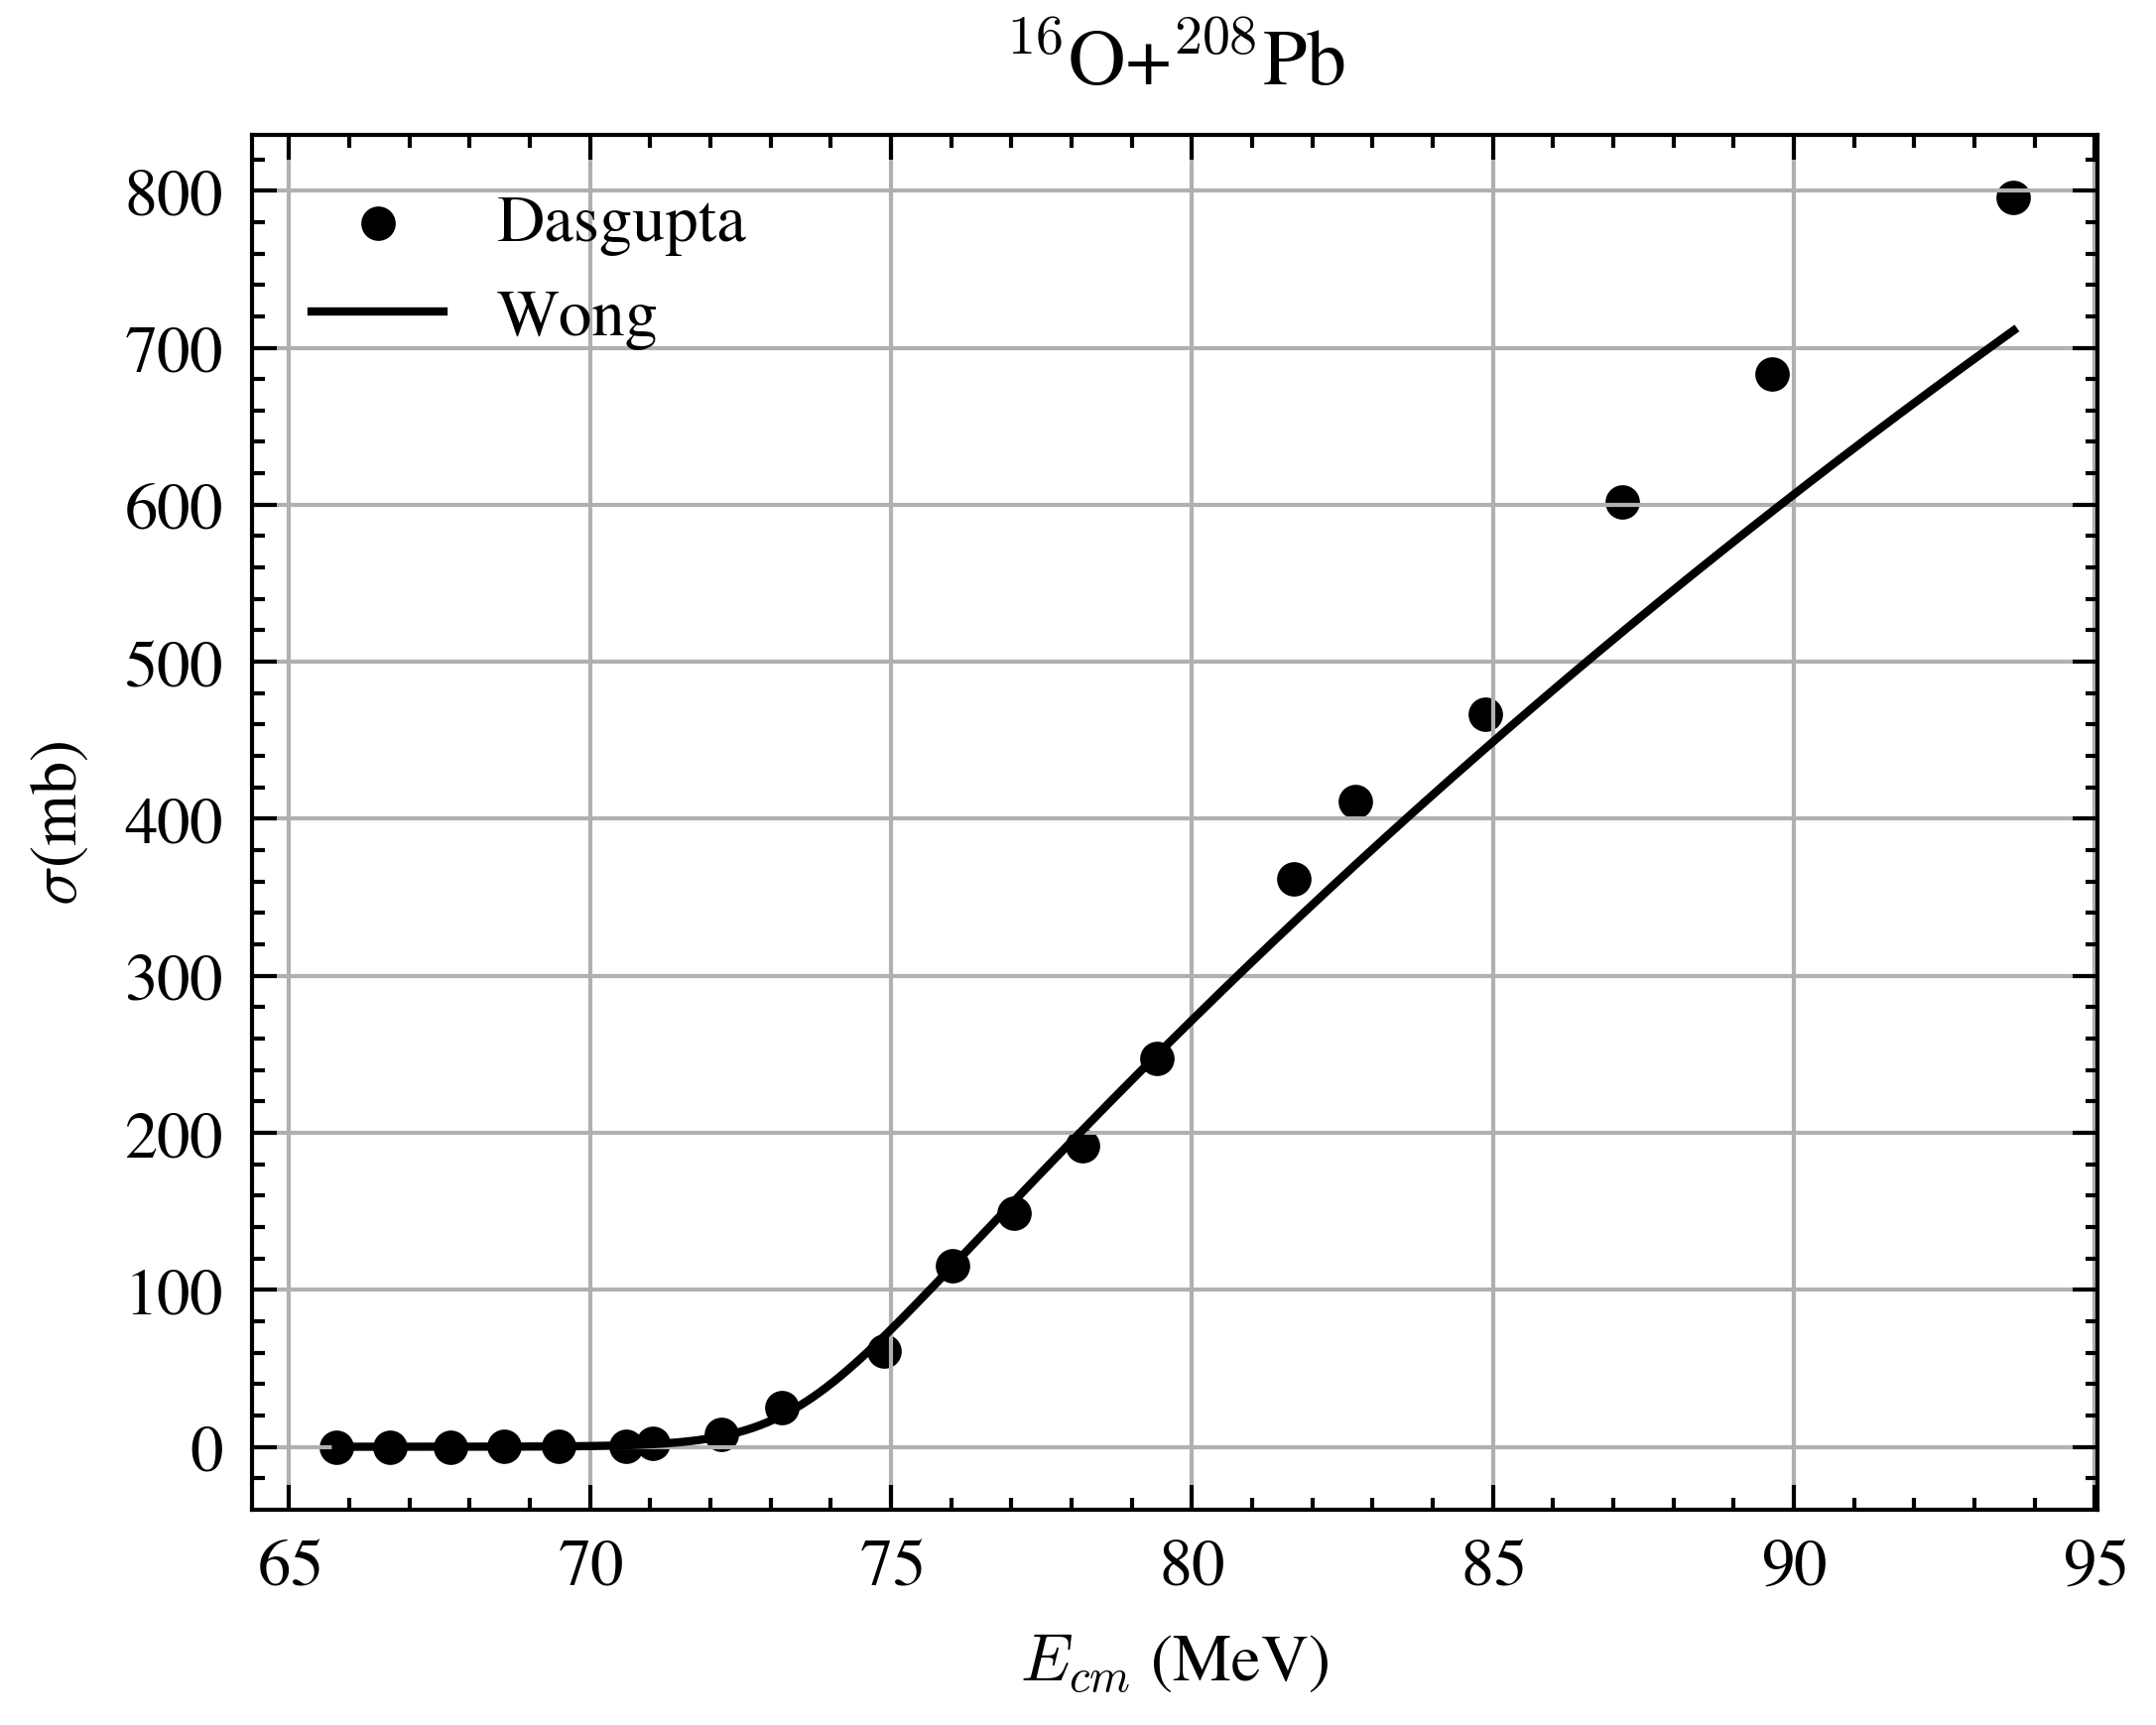

In [4]:
E_data_1 = exp[1]['Ecm'].to_numpy()
Sigma_data_1 = exp[1]['Sigma'].to_numpy()
#Sigma_err  = exp[1]['Error'].to_numpy()

# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess_1 = [72.0, 11.0, 5]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt_1, pcov_1 = curve_fit(
    sigma,
    E_data_1,
    Sigma_data_1,
    p0=initial_guess_1,
    #sigma=Sigma_err,
    #absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 0.0, 0.0], [np.inf, 20.0, np.inf])
)

E0_opt_1, R0_opt_1, hbarw_opt_1 = popt
perr_1 = np.sqrt(np.diag(pcov_1))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt_1:.4f} ± {perr_1[0]:.4f}")
print(f"  R0    = {R0_opt_1:.4f} ± {perr_1[1]:.4f}")
print(f"  hbarw = {hbarw_opt_1:.4f} ± {perr_1[2]:.4f}")

# --- Plot experiment vs. fit ---
E_plot_1 = np.linspace(E_data_1.min(), E_data_1.max(), 500)
Sigma_fit_1 = sigma(E_plot_1, E0_opt_1, R0_opt_1, hbarw_opt_1)

plt.figure(figsize=(4,3))
#plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
plt.scatter(E_data_1, Sigma_data_1, label='Dasgupta', color='k', s=10)
plt.plot(E_plot_1, Sigma_fit_1, label='Wong')
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

### Sample several reasonable cross sections across fit parameters using the covariance matrix to determine uncertainties

In [5]:
N = 1000
total_E = np.concatenate((exp[0]['Ecm'].to_numpy(), exp[1]['Ecm'].to_numpy()))
E_fine = np.linspace(total_E.min(), total_E.max(), N)

# Number of Monte‐Carlo draws to propagate parameter‐uncertainty:
M = 200 

# Covariance of (E0,R0,hbarw) from your fit:
P_cov = pcov        # shape (3,3) 

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  1) Draw M parameter‐samples from  N(popt, pcov)                             │
# └─────────────────────────────────────────────────────────────────────────────┘
# Each row of `param_samples` is (E0_j, R0_j, hbarw_j).
param_samples = np.random.multivariate_normal(
    mean=[E0_opt, R0_opt, hbarw_opt],
    cov=P_cov,
    size=M
)  # shape (M,3)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  2) For each of those M sets, compute σ_j(E_data)                            │
# └─────────────────────────────────────────────────────────────────────────────┘
# We'll build a matrix S of shape (M, N) where
#    S[j,i] = σ( E_fine[i];  E0_j, R0_j, hbarw_j ).
S = np.empty((M, N))

for j in range(M):
    E0_j, R0_j, hbarw_j = param_samples[j]
    # Evaluate your analytic sigma‐function on the entire E_fine grid:
    S[j, :] = sigma(E_fine, E0_j, R0_j, hbarw_j)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  3) Compute the Monte‐Carlo mean and variance at each E_data[i]               │
# └─────────────────────────────────────────────────────────────────────────────┘
#   mean over j:  shape → (N,)
sigma_mean = S.mean(axis=0)
#   var  over j:  shape → (N,)
sigma_var  = S.var(axis=0, ddof=1)   # unbiased estimate of Var[σ(E_i)]

# If any σ_var[i] happens to be exactly zero (i.e. all S[:,i] identical),
# add a tiny floor so the GP doesn't complain about zero‐noise.
sigma_var += 1e-16

In [6]:
#from src.train import train_gp
from src.plot import plot_gp_with_data

def train_gp(E_train, sigma_mu_train, delta_sigma_train, n_restarts=20, kernel=None):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise.

    Parameters
    ----------
    E_train : array-like, shape (N,)
        Training energies.
    sigma_mu_train : array-like, shape (N,)
        Mean cross-section values at E_train.
    delta_sigma_train : array-like, shape (N,)
        Variance of cross-section at E_train (i.e., noise variances).
    n_restarts : int, optional (default=10)
        Number of restarts for the optimizer.

    Returns
    -------
    gp : GaussianProcessRegressor
        The fitted GP model.
    """
    # 1) Sort E_train for length-scale estimation
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = max(np.median(dE), 1e-6)
    lbound, ubound = ell0 / 10.0, ell0 * 10.0

    # 2) Compute signal variance from the training mean
    var_y0 = np.var(sigma_mu_train)
    print(var_y0)

    if kernel is None:
        # 3) Build kernel: Constant * RBF  + WhiteKernel
        k_rbf   = ConstantKernel() * RBF(length_scale=1.0, )#length_scale_bounds=(lbound, ubound)) # *ConstantKernel(constant_value=var_y0, constant_value_bounds=(var_y0/100, var_y0*100)) 
        k_noise = WhiteKernel(noise_level=1e-5 , noise_level_bounds=(1e-9, 1e-5))
        kernel  = k_rbf #+k_noise

    # 4) Instantiate and fit GP
    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=np.asarray(delta_sigma_train)**2,
        normalize_y=False,
        n_restarts_optimizer=n_restarts
    )
    gp.fit(np.asarray(E_train).reshape(-1, 1), np.asarray(sigma_mu_train))
    return gp



# Create a training set for the GP:
fine_interval = 10
coarse_interval = 50
start = 0#np.argmin(np.abs(E_fine - 75.0))
mid = np.argmin(np.abs(E_fine- 80.0))
stop = np.argmin(np.abs(E_fine- 90.0))
E_train = np.concatenate((E_fine[start:mid:fine_interval], E_fine[mid:-1:coarse_interval]))
#E_train = E_fine[start:stop:interval]

sigma_train = np.concatenate((sigma_mean[start:mid:fine_interval], sigma_mean[mid:-1:coarse_interval]))#sigma_mean[start:stop:interval]
sigma_train_var = np.concatenate((sigma_var[start:mid:fine_interval], sigma_var[mid:-1:coarse_interval]))#sigma_var[start:stop:interval]
gp = train_gp(E_train, sigma_train, sigma_train_var)


107867.401134646


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [7]:
gp.log_marginal_likelihood()

-354.601741326504

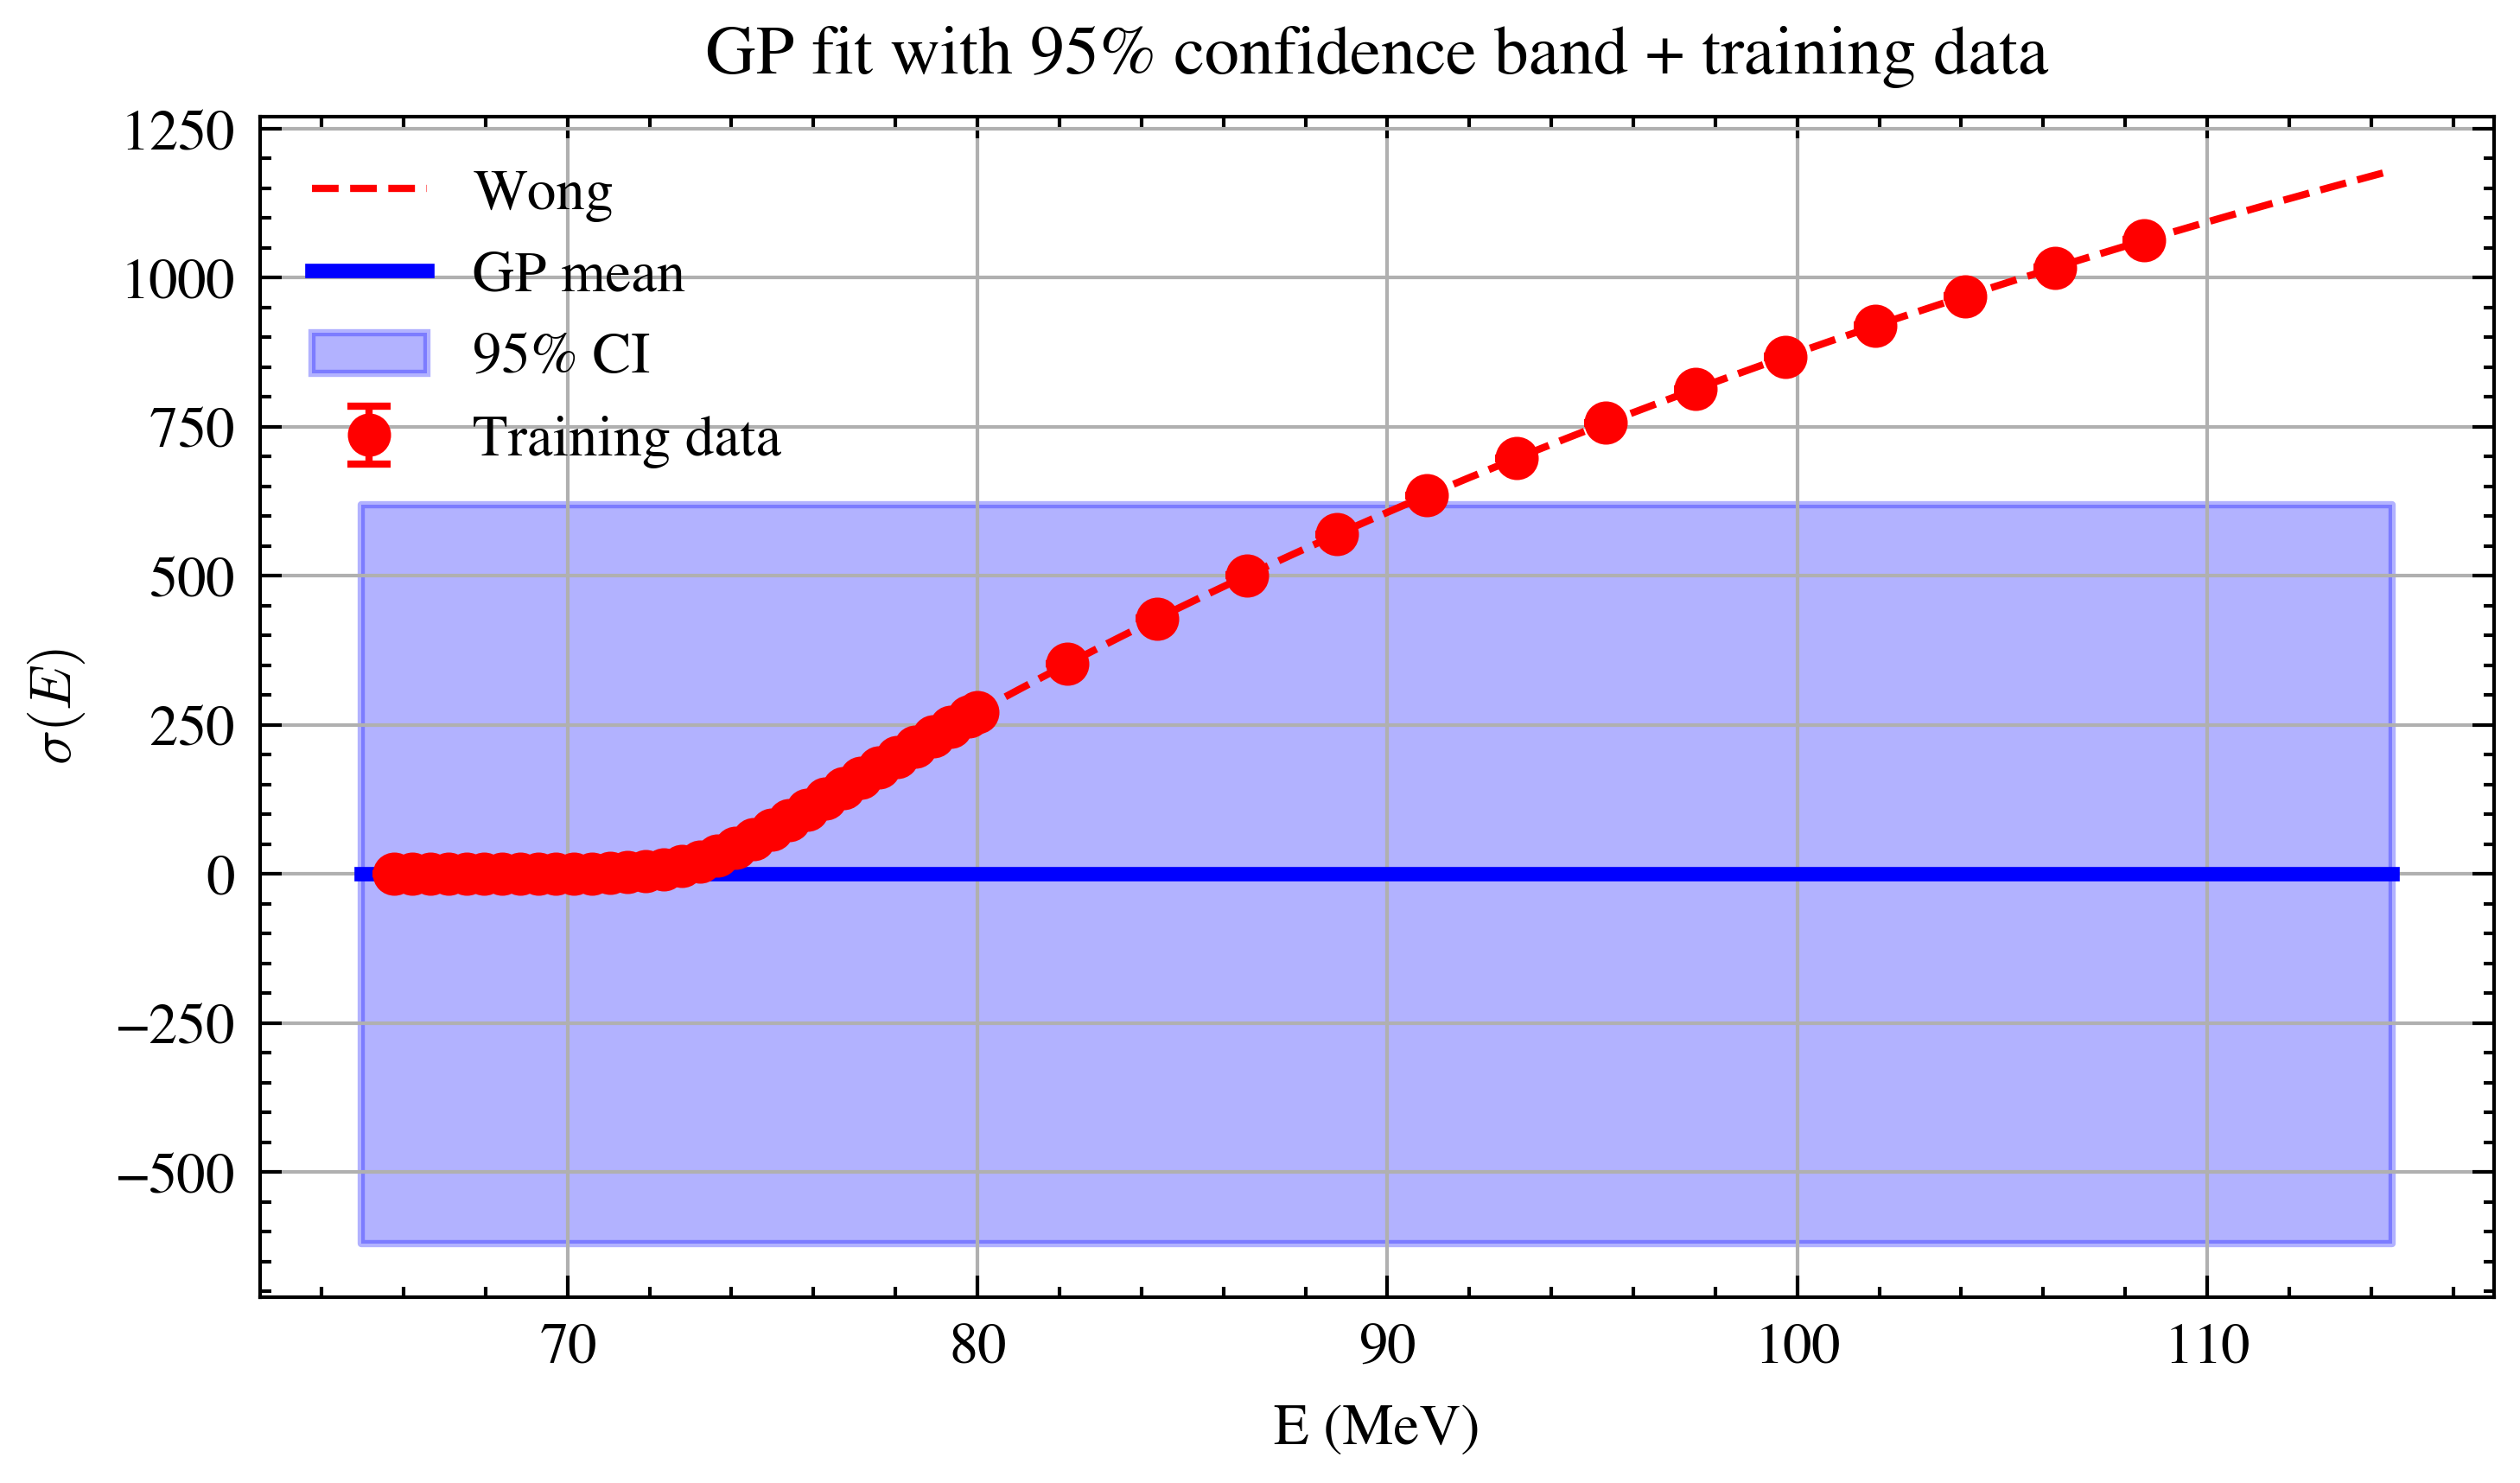

In [8]:
E_eval = np.linspace(E_data.min()-5, E_data.max()+5, 500)
# Plot the GP with the training data and the uncertainty:
plt.figure(figsize=(5, 3))
plt.plot(E_eval, sigma(E_eval, E0_opt, R0_opt, hbarw_opt), label='Wong', color='C1', linestyle='--')
plot_gp_with_data(gp, E_plot=E_eval, E_train=E_train, sigma_mu_train=sigma_train, delta_sigma_train=sigma_train_var)

plt.show()

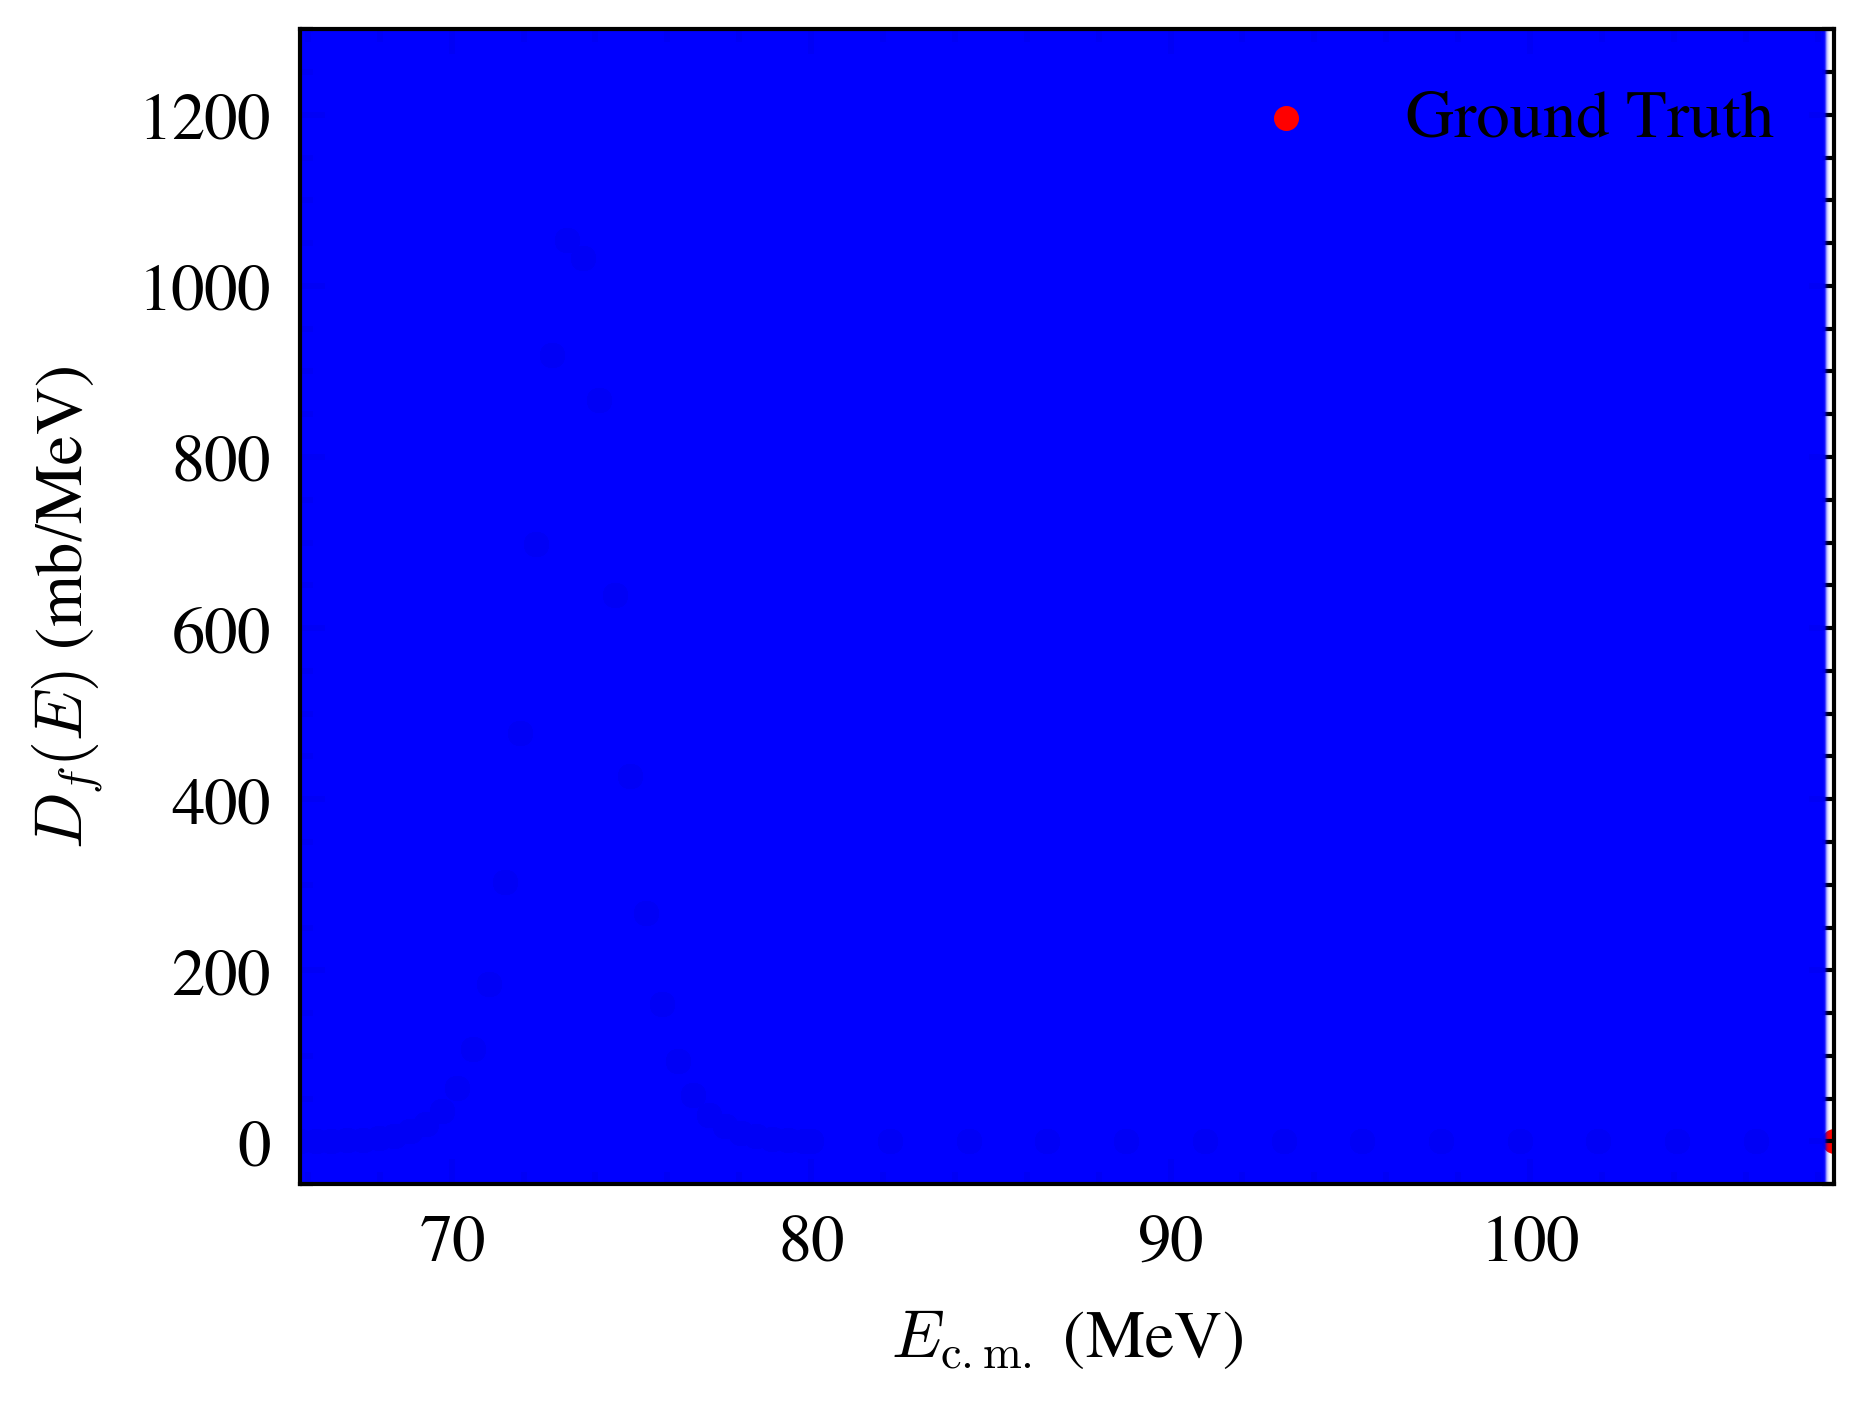

In [9]:
from src.utils import barrier_dist, point_diff
E_dist = np.arange(E_train[0],E_train[-1], 0.15)
n_samples=100
n_cut=0
y_samples = gp.sample_y(E_dist.reshape(-1,1), n_samples=n_samples)
ndist = np.zeros((len(E_dist),n_samples))
for i in range(n_samples):
    ndist[:,i] = barrier_dist(E_dist,y_samples[:,i],acc=4)
    plt.plot(E_dist[n_cut:-n_cut-1],ndist[n_cut:-n_cut-1,i],marker="",ls='-',lw=1,ms=0,alpha=0.1, color='b')

true_d = barrier_dist(E_fine,sigma(E_fine,E0_opt,R0_opt,hbarw_opt),acc=4)
idx    = np.searchsorted(E_fine, E_train)
true = true_d[idx]

#true = barrier_dist(E_train,sigma(E_train,E0_opt,R0_opt,hbarw_opt),acc=4)
#plt.plot(E_dist[5:-5:10],true[5:-5:10],linestyle='--',color='r',label=r'True $D_{f}(E)$')
spacing = 1
plt.scatter(E_train[::spacing],true[::spacing],marker='o',color='r',label=r'Ground Truth', s=4)

plt.legend()
plt.ylabel(r'$D_f(E)$ (mb/MeV)')
plt.xlim(E_train[0], E_train[-1])
plt.ylim(-50,1300)
plt.xlabel(r'$E_{\mathrm{c.m.}}$ (MeV)')

plt.show()


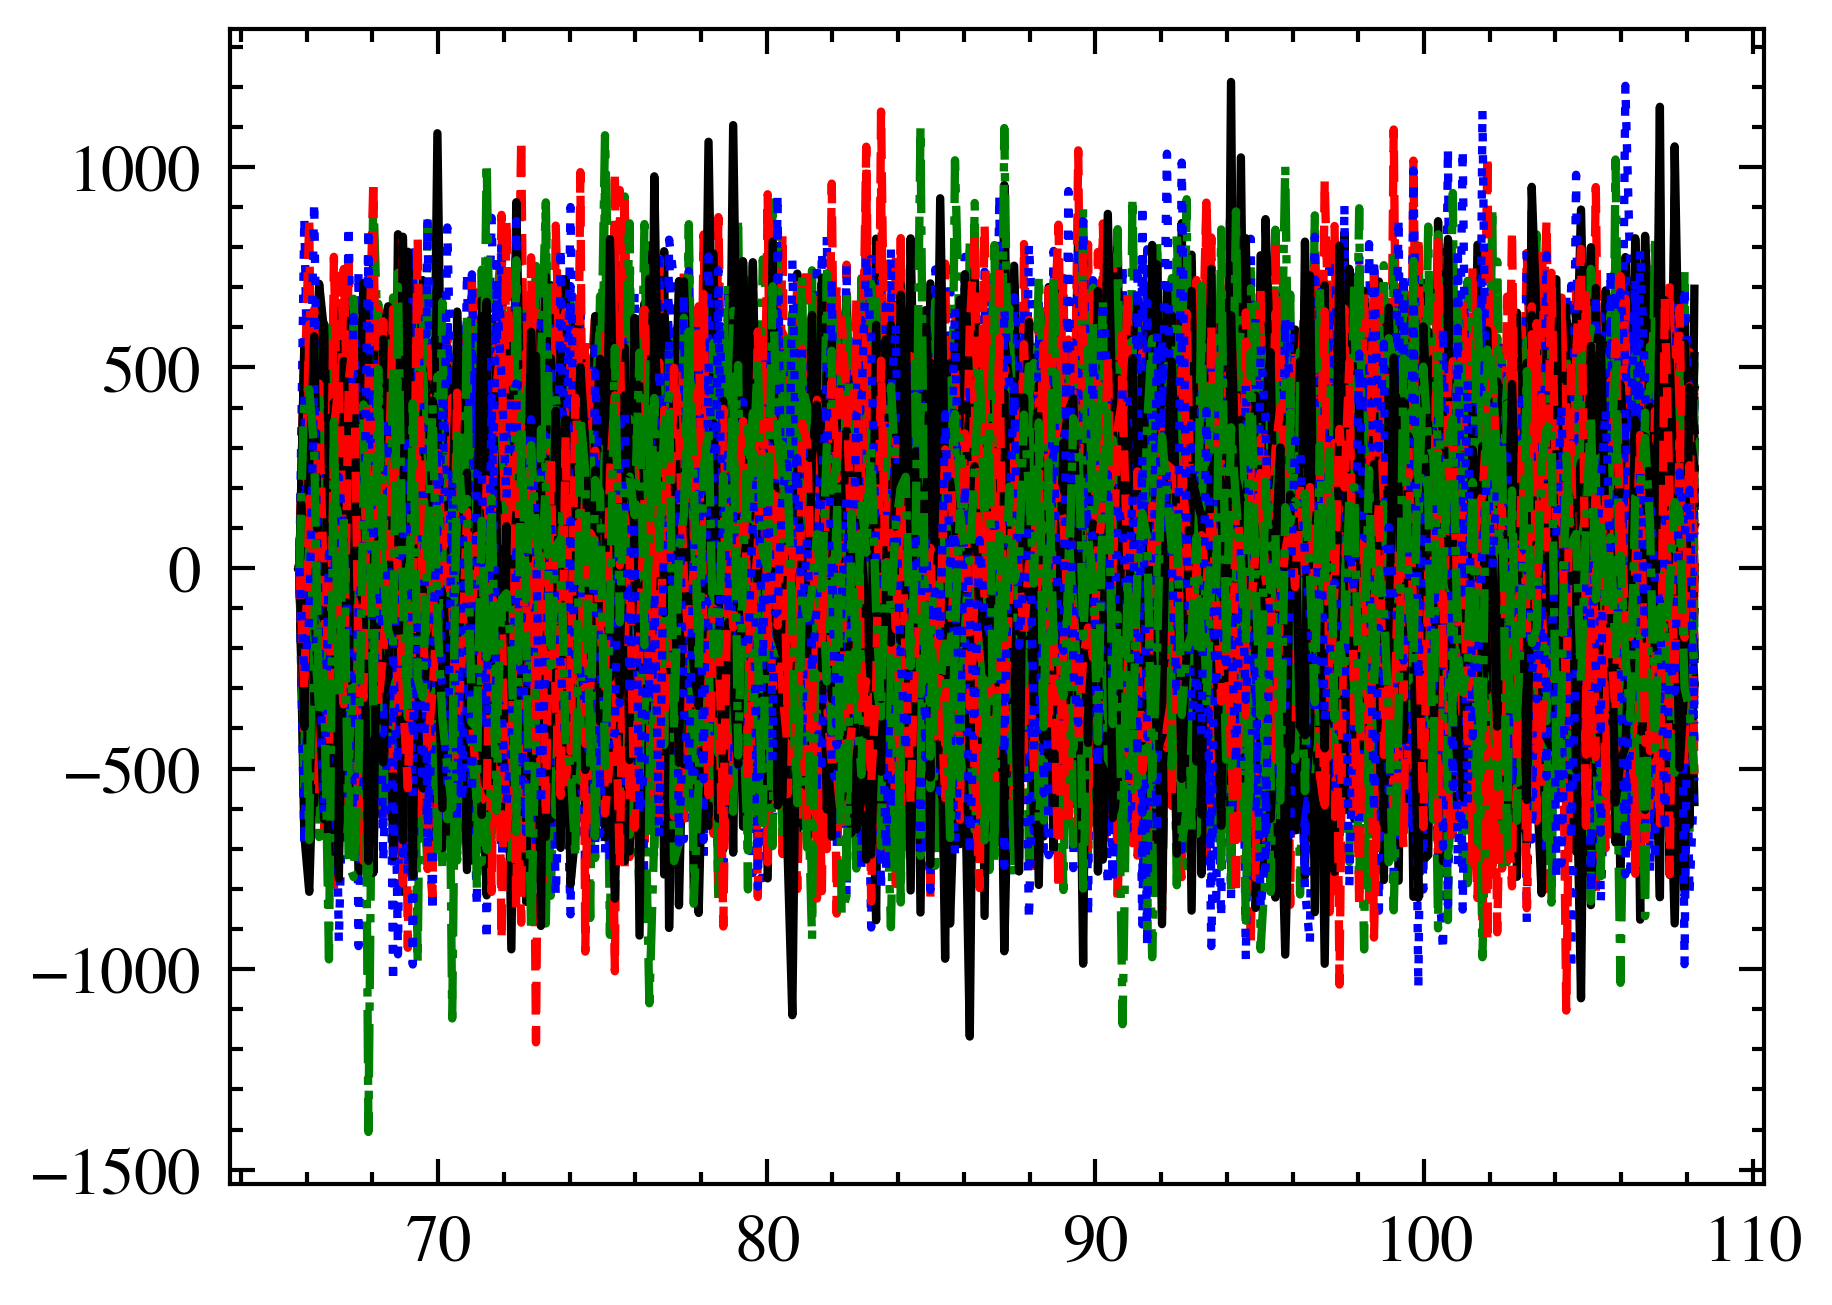

In [10]:
for i in range(n_samples):
    plt.plot(E_dist[n_cut:-n_cut-1], y_samples[n_cut:-n_cut-1,i])

# AutoBNN 

In [32]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import sys
if "/Users/aaronphilip/Senior Thesis/probability/spinoffs/autobnn" not in sys.path:
    sys.path.insert(0, "/Users/aaronphilip/Senior Thesis/probability/spinoffs/autobnn")
import autobnn
from autobnn import estimators, training_util
from autobnn import kernels, likelihoods

# 1) Initialize PRNG
seed = jax.random.PRNGKey(0)

# 3) Normalize inputs once
x_scale = np.std(E_train)
x_shift = np.mean(E_train)
y_scale = np.std(sigma_train)
y_shift = np.mean(sigma_train)

x_norm = ((E_train - x_shift) / x_scale)[..., None]
y_norm = ((sigma_train-y_shift) / y_scale)[..., None]

# 4) Build & train the AutoBnnMapEstimator
seed, est_seed = jax.random.split(seed)
rbf = kernels.ExponentiatedQuadraticBNN()

bnn_est = estimators.AutoBnnMCMCEstimator(
    'sum_of_products',              
    likelihood_model='normal_likelihood_lognormal_noise',
    seed=est_seed,
    width=50,
    num_chains=4,
    num_draws=50,
    num_warmup=1000,
    distributed=1
)
"""
bnn_est = estimators.AutoBnnMapEstimator(
    rbf,#'sum_of_products',              
    likelihood_model='normal_likelihood_logistic_noise',
    seed=est_seed,
    width=50,
    num_iters= 5000,
    num_particles = 100,
)
"""
bnn_est = bnn_est.fit(x_norm, y_norm)

Using Custom MCMC


sample: 100%|██████████| 1050/1050 [17:29<00:00,  1.00it/s]


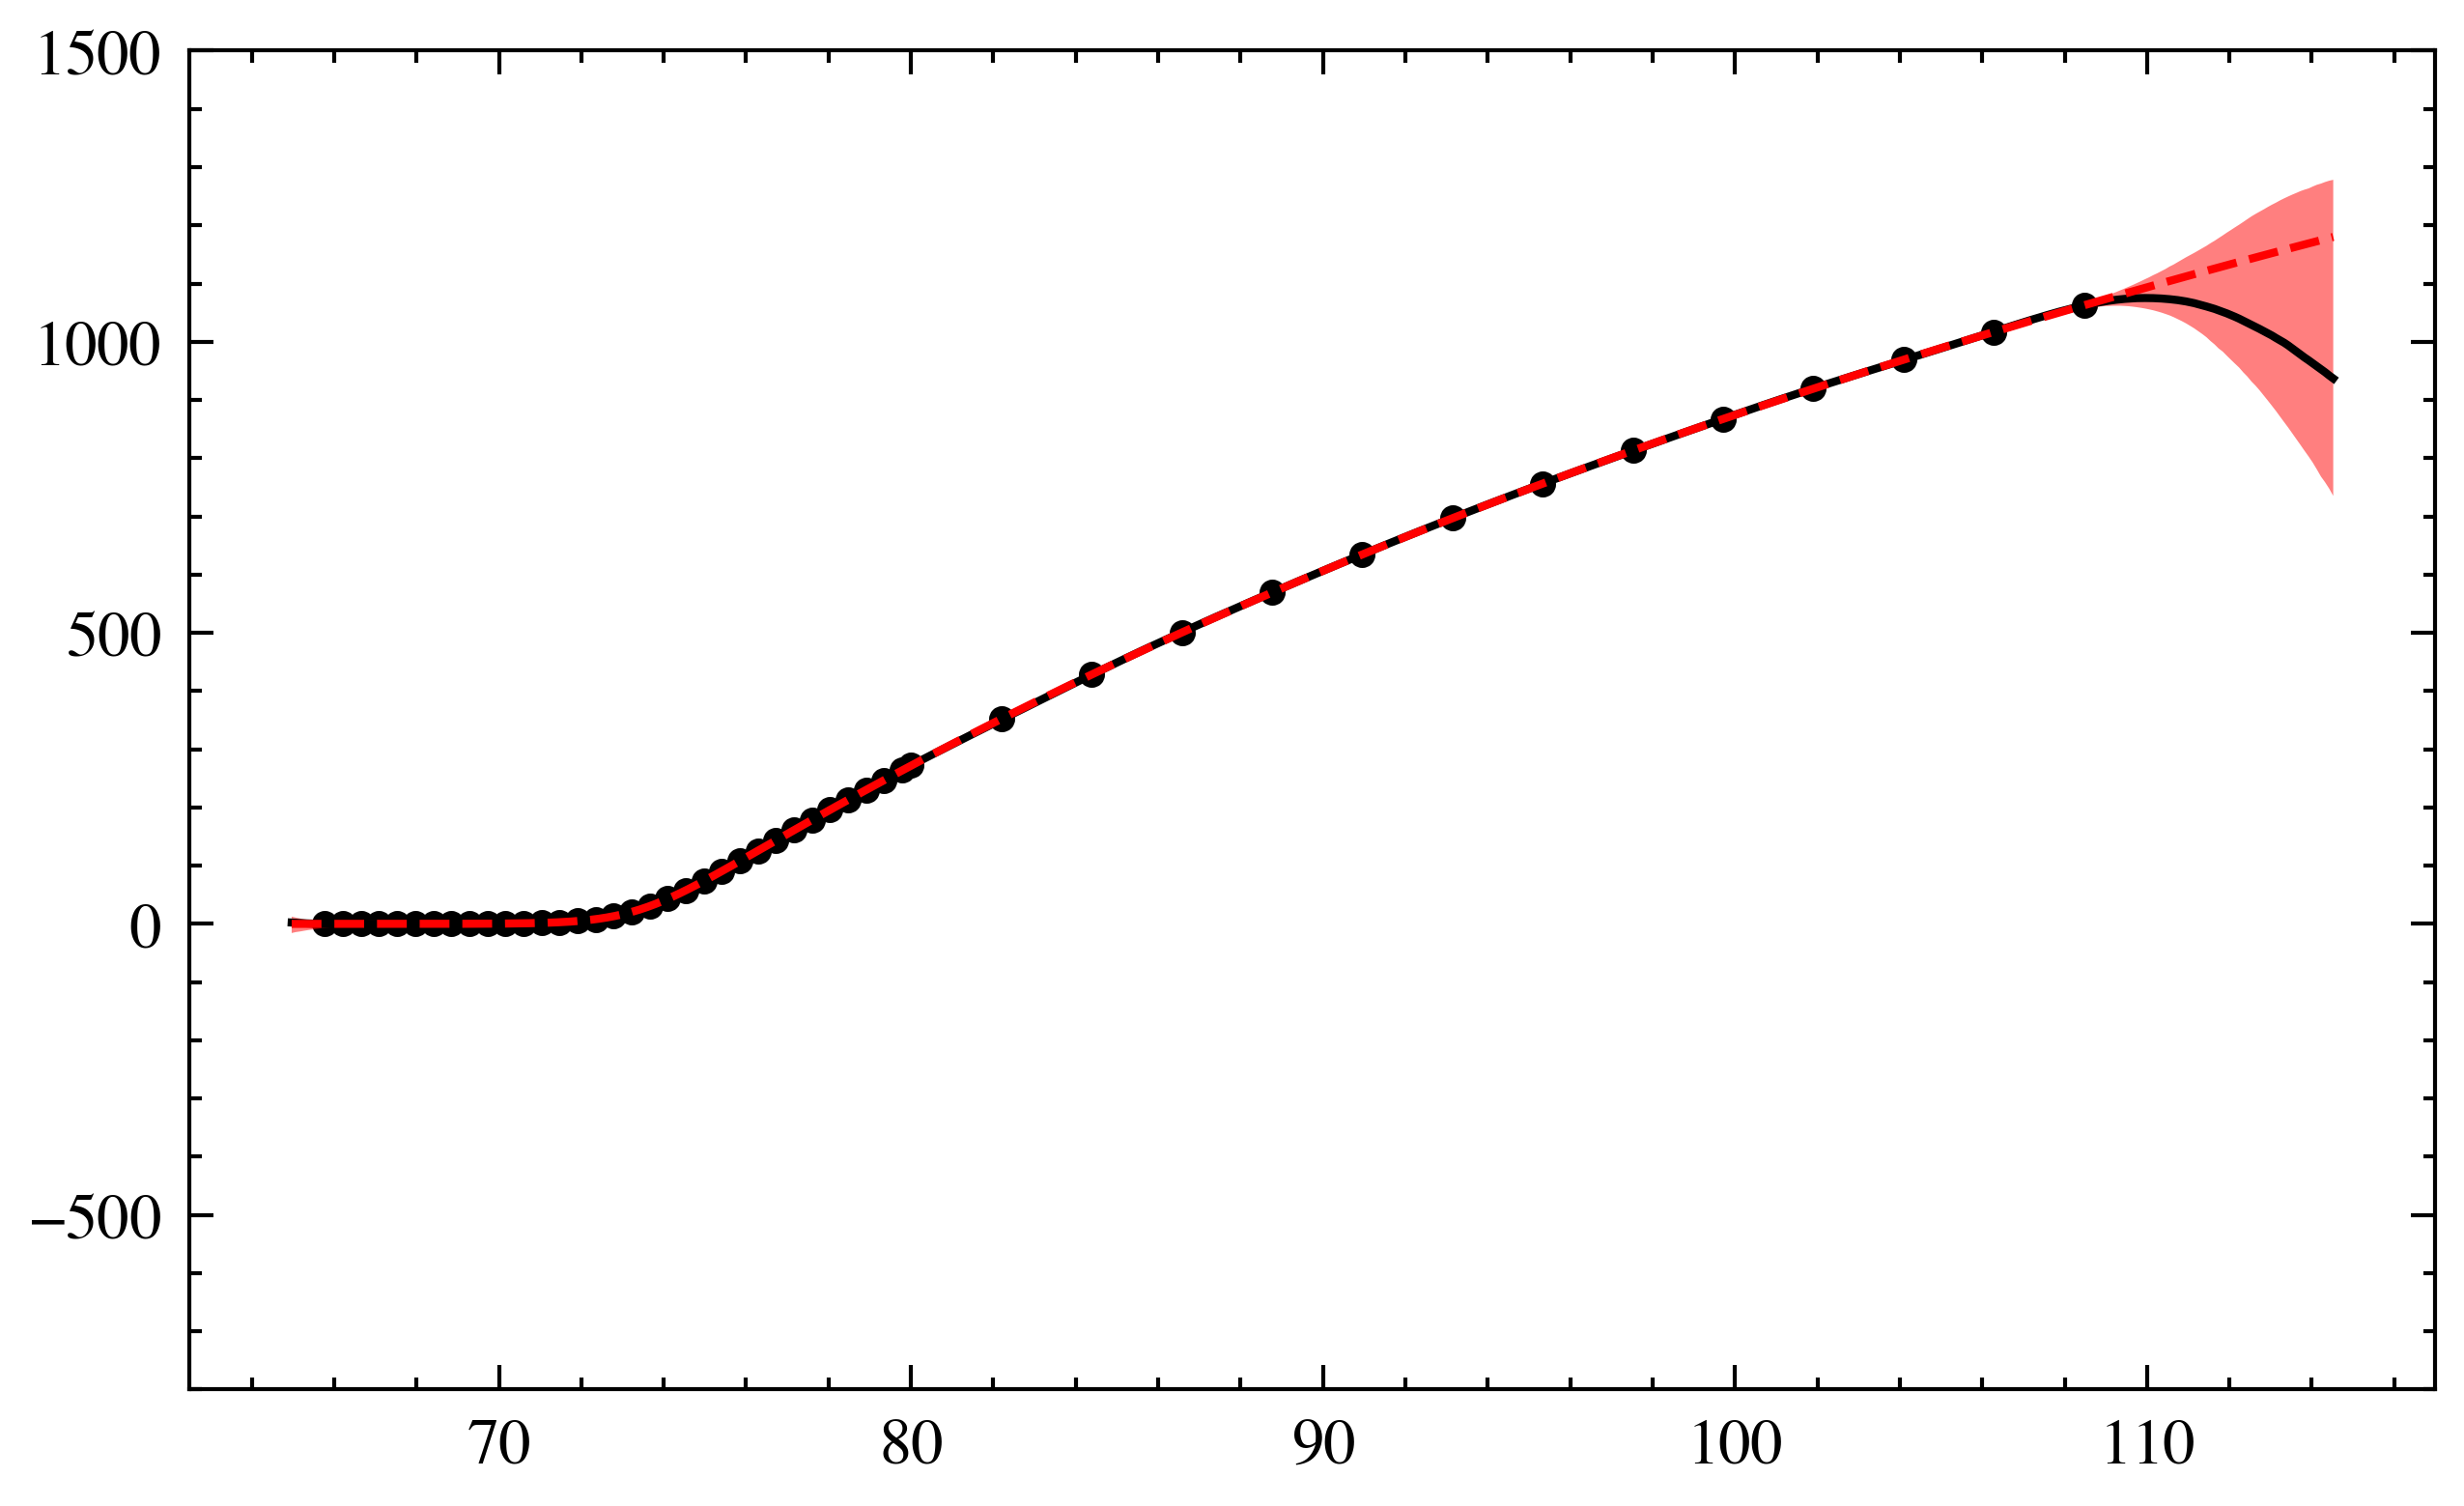

In [25]:
# 5) Prediction grid (physical → normalized)
x_pred = E_eval #np.linspace(E_train.min(), E_train.max(), 99)
x_pred_norm = (x_pred- x_shift) / x_scale

# 6) Get per-particle means and noise‐draws
#    estimator.predict returns a dict with keys 'mean' and 'std' of shape (num_particles, n_x)
pred = bnn_est.predict(x_pred_norm[..., None]) * y_scale + y_shift
# Draw 100 noisy samples per particle
seed, draw_seed = jax.random.split(seed)
# we broadcast sample_shape over both axes

lo, mid, p90, hi = bnn_est.predict_quantiles(x_pred_norm[..., None], q=[2.5, 50., 90., 97.5]) * y_scale + y_shift

plt.figure(figsize=(5, 3))
plt.plot(x_pred, mid.squeeze(), label="BNN")
plt.plot(E_eval, sigma(E_eval, E0_opt, R0_opt, hbarw_opt), label='Wong', color='C1', linestyle='--')
plt.scatter(E_train, sigma_train, s=5)
plt.fill_between(
    x_pred,
    lo.squeeze(), hi.squeeze(),
    alpha=0.5,
    label="95% confidence BNN ",
)
plt.ylim(-800, 1500)
plt.show()

In [20]:
bnn_est.net_.summarize()

'RBF'

(100, 400, 500)


(-800.0, 1500.0)

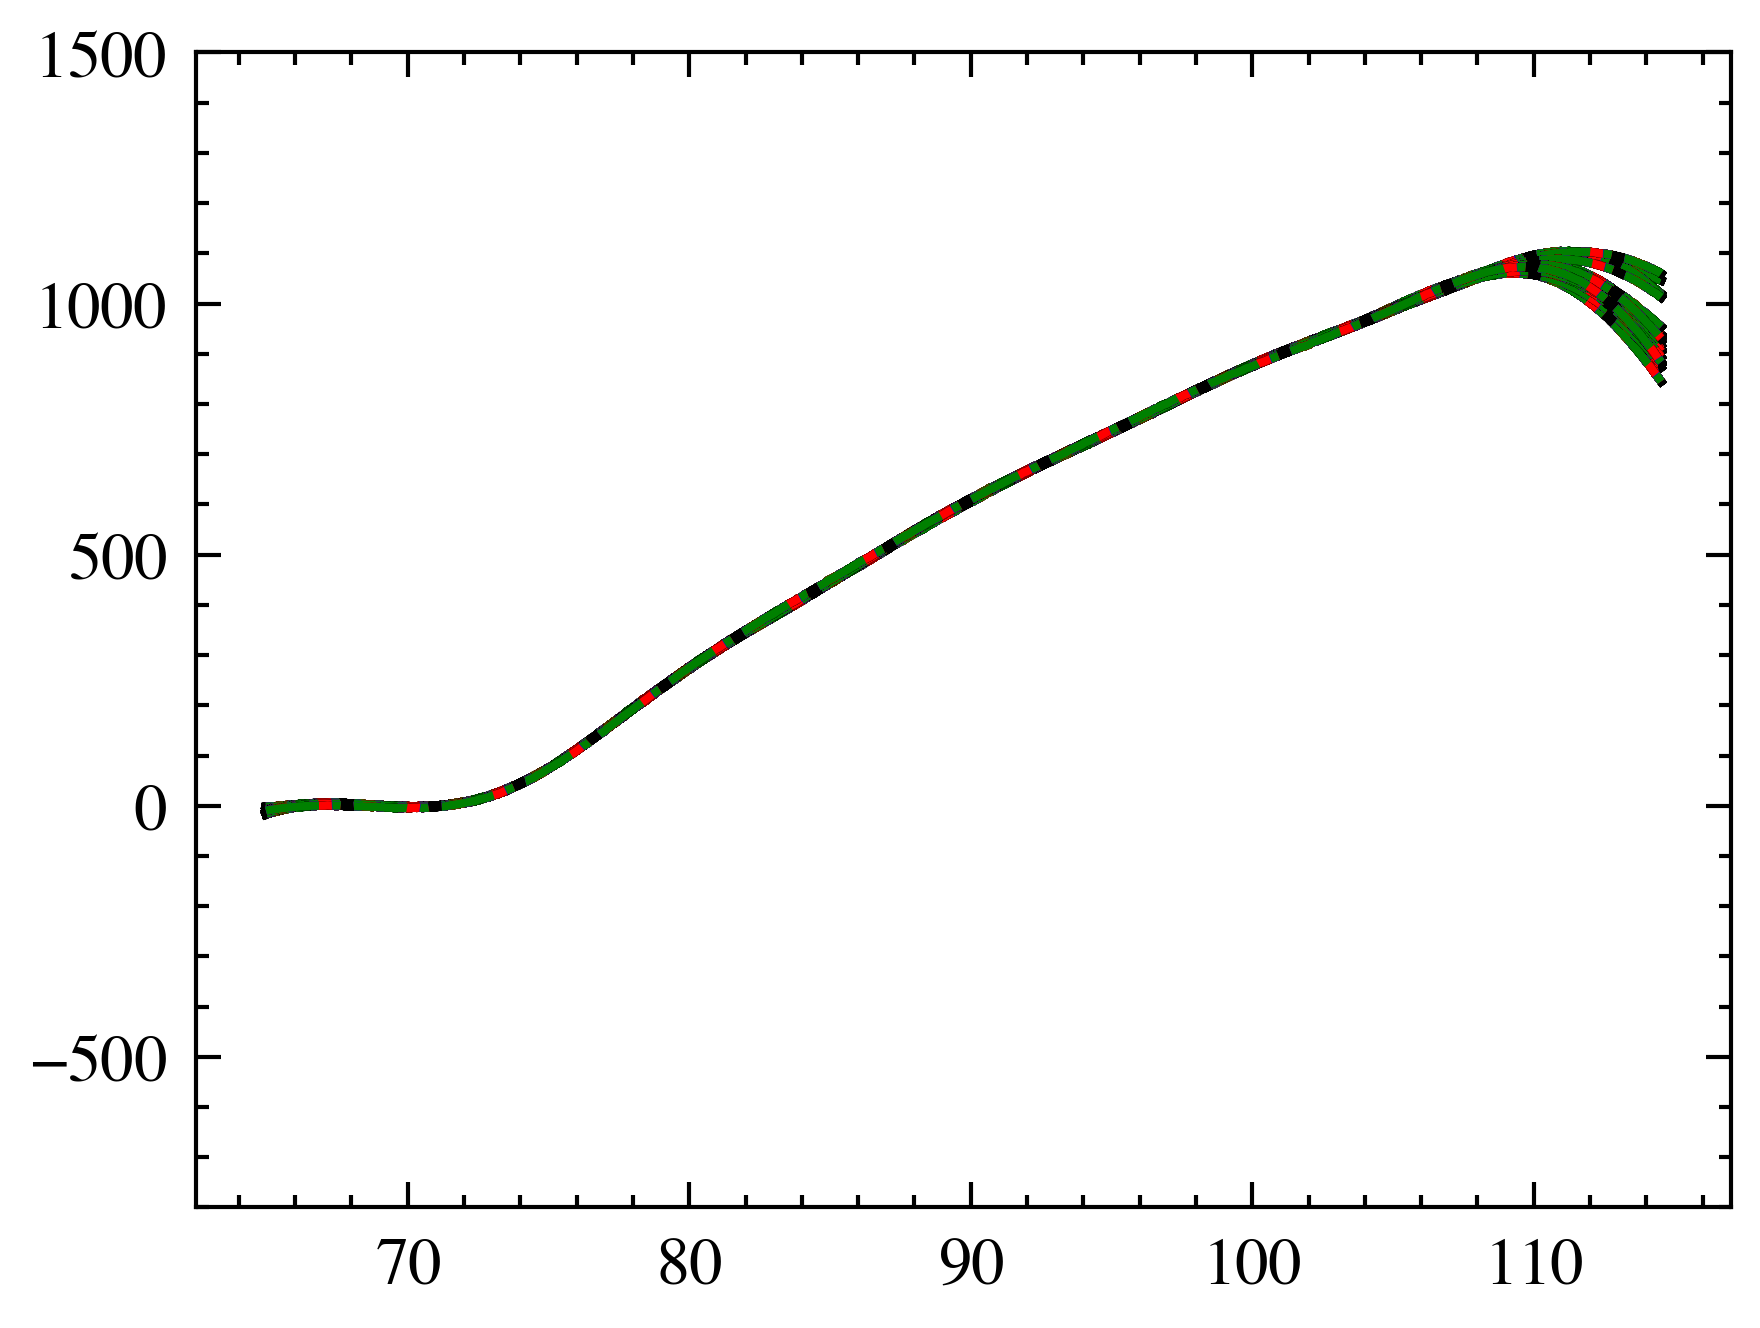

In [26]:
draws = bnn_est.likelihood_.sample(
                    bnn_est.params_['params'], pred.squeeze(), seed=seed, sample_shape=100)
draws = draws.squeeze()
print(draws.shape)
n_particle = 0
for n_particle in range(20):
    for i in range(draws.shape[0]):
        plt.plot(E_eval, draws[i,n_particle,:])
plt.ylim(-800, 1500)

Total posterior samples: 100
(100, 500)
(100, 500)


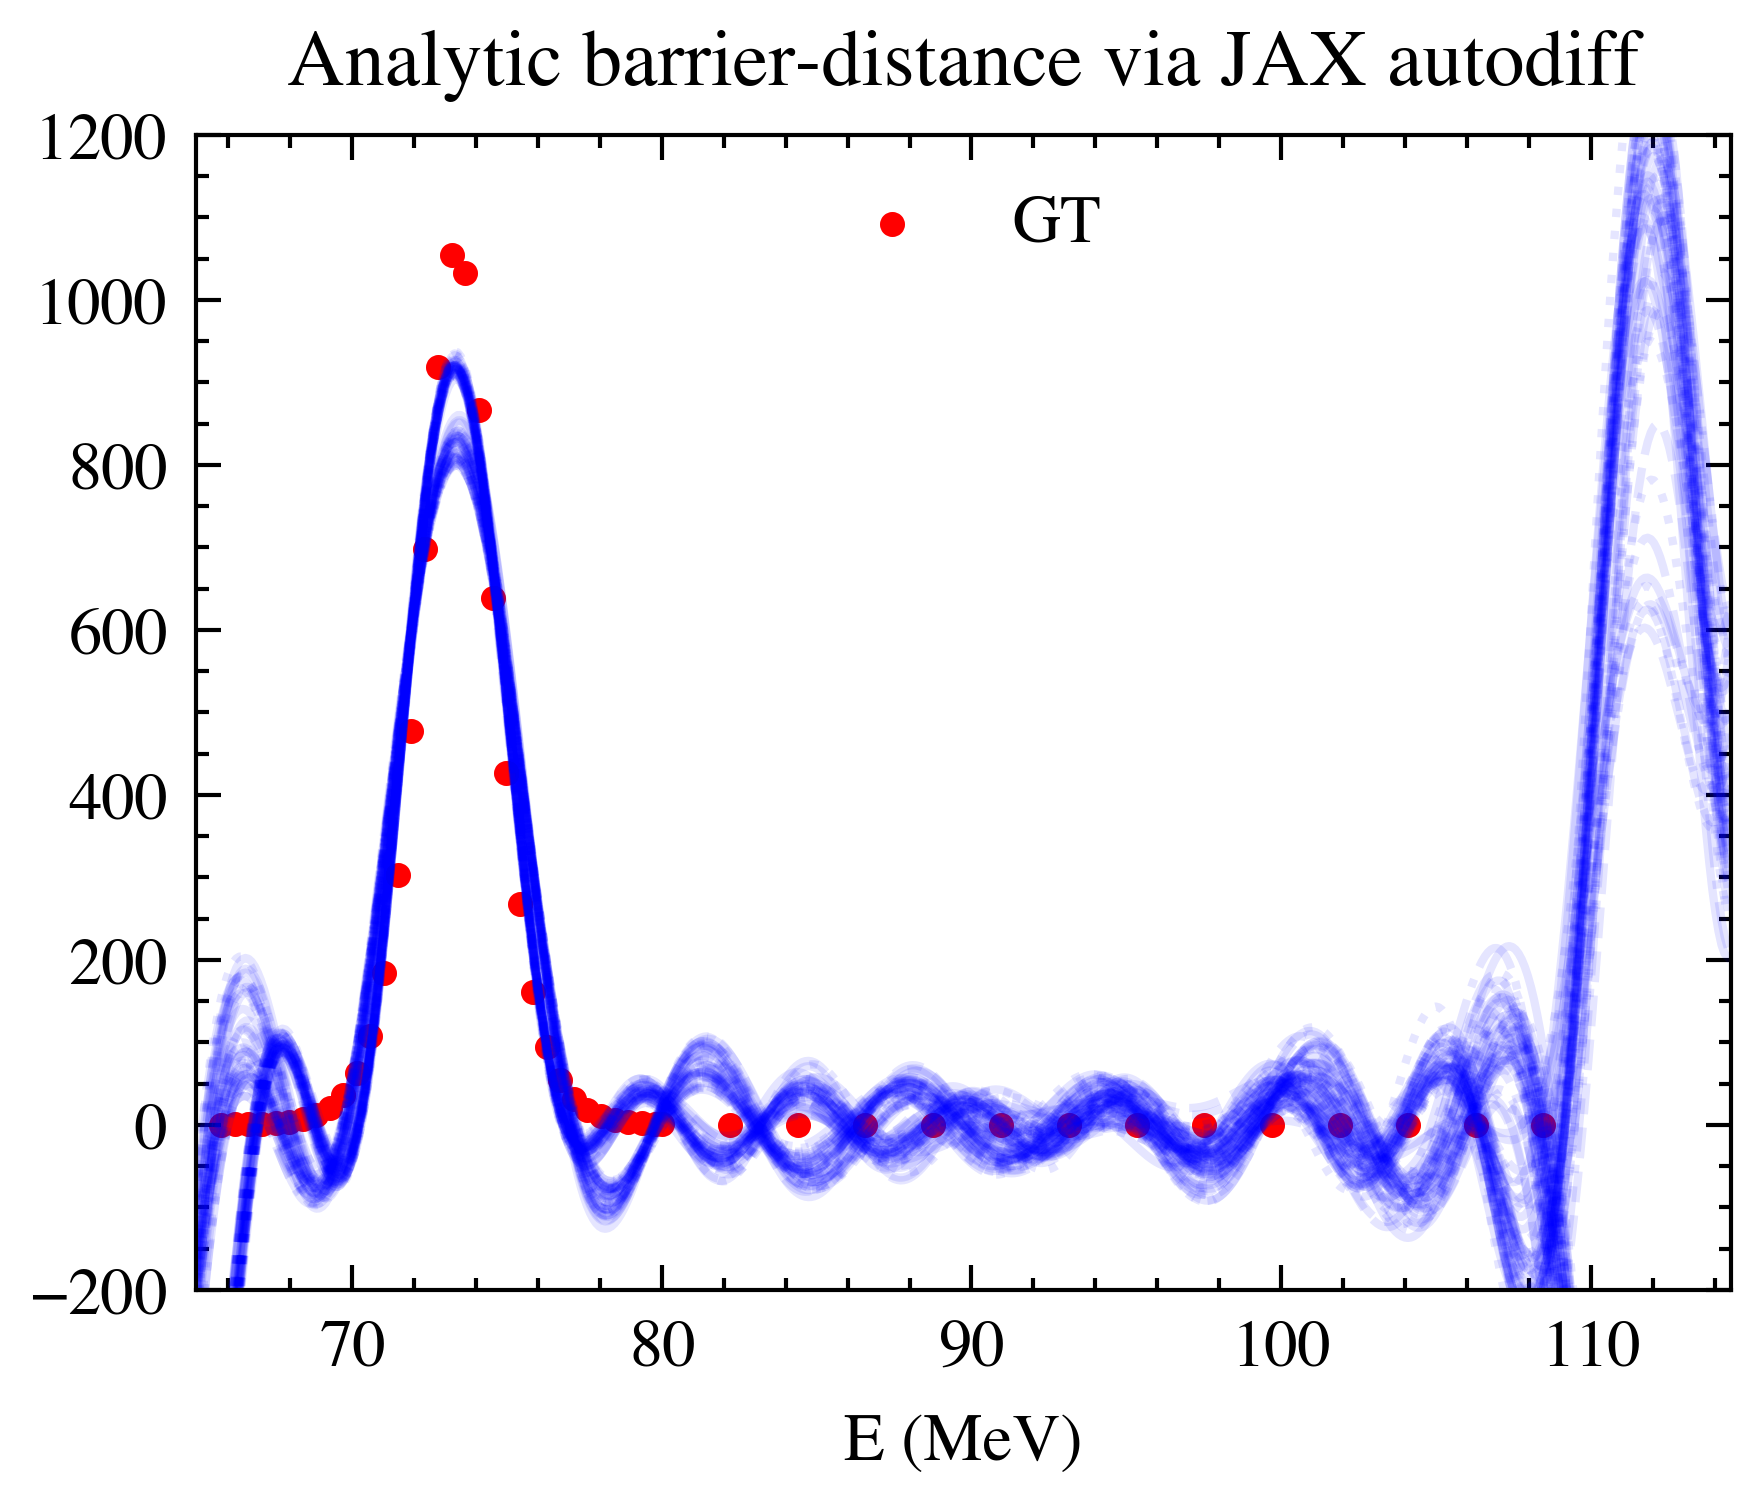

In [33]:
x_pred = E_eval
seed, draw_seed = jax.random.split(seed)
def f_single_sample(params, x_scalar):
    # Ensure x_scalar has shape (1, features) since the model expects a batch
    x_norm = jnp.array([[(x_scalar - x_shift) / x_scale]])
    x_batch = jnp.atleast_2d(x_norm)  # shape (1, 1) for a single scalar input
    pred = bnn_est.net_.apply(params, x_batch)  # model prediction, shape (1, 1)
    return pred.squeeze()*y_scale + y_shift
 
def g(params, x_scalar):
    return x_scalar * f_single_sample(params, x_scalar)

grad_g_wrt_x = jax.grad(g, argnums=1)
# Second derivative of g w.rt x
grad2_g_wrt_x = jax.grad(grad_g_wrt_x, argnums=1)

X_vals = x_pred.squeeze()  # shape (n,) for convenience
# Pull out all the leaf arrays
leaves = jax.tree_util.tree_leaves(bnn_est.params_)

# Assume every leaf has shape (n_samples, …); take n_samples from the first leaf
n_samples = leaves[0].shape[0]
print("Total posterior samples:", n_samples)

params_samples = bnn_est.params_ 

# Vectorize over x (inner vmap), for a fixed params:
def second_deriv_for_one_sample(params):
    return jax.vmap(lambda x: grad2_g_wrt_x(params, x))(X_vals)
# Now vectorize over samples (outer vmap):
all_second_derivs = jax.vmap(second_deriv_for_one_sample)(params_samples)
print(all_second_derivs.shape)

import jax.random as jr
key, subkey = jr.split(seed)
n_samples = all_second_derivs.shape[0]
idx = jr.choice(subkey, n_samples, (100,), replace=False)
all_second_derivs = all_second_derivs[idx]

print(all_second_derivs.shape)
# 4) Plot exactly as you did before

plt.figure()
n_cut = 0
for p in range(all_second_derivs.shape[0]):
    y = np.array(all_second_derivs[p, n_cut:-n_cut-1])
    plt.plot(x_pred[n_cut:-n_cut-1], y, lw=1, alpha=0.1, color='b')

# if you have ground truth:
plt.scatter(E_train[::spacing], true[::spacing], color='r', s=4, label='GT')

plt.xlabel("E (MeV)")
#plt.ylabel(r"$\dfrac{d^2}{dE^2}\bigl[E\,\sigma(E)\bigr]$")
plt.title("Analytic barrier-distance via JAX autodiff")
plt.ylim([-200, 1200])
plt.xlim(E_eval[0], E_eval[-1])
plt.legend()
plt.show()


In [16]:
"""
draws = bnn_est.likelihood_.sample(
                    bnn_est.params_['params'], pred.squeeze(), seed=seed, sample_shape=100)
#draws = draws.reshape(-1, draws.shape[-1])

# number of particles
P = draws.shape[1]

# shortcut to the trained net and params
net    = bnn_est.net_
params = bnn_est.params_


# 1) Define a scalar function for a single particle i:
#    f_i(x) = x * σ_p(x), where σ_p is the BNN mean for particle p=i.
def f_i(i, x):
    # normalize and shape for predict:
    x_norm = jnp.array([[(x - x_shift) / x_scale]])
    # make_predictions returns shape (P, 1, 1)  => loc[p,0,0] is σ_p(x_norm)
    loc = training_util.make_predictions(params, net=net, x_test=x_norm)*y_scale + y_shift
    return x * loc[i, 0, 0]   # scalar

# 2) Build a jitted function that for a given i and x returns d²f_i/dx²
#    by nesting two grads.
d2_f_i = jax.jit(
    lambda i, x: jax.grad(jax.grad(lambda xx: f_i(i, xx), argnums=0), argnums=0)(x)
)

# 3) Vectorize over particle index i and then over x_pred
#    Result will be shape (P, n_x)
d2_over_particles = jax.vmap(
    lambda i: jax.vmap(lambda xx: d2_f_i(i, xx))(x_pred),
    in_axes=0
)(jnp.arange(P))

# 4) Plot exactly as you did before
plt.figure()
n_cut = 0
for p in range(P):
    y = np.array(d2_over_particles[p, n_cut:-n_cut-1])
    plt.plot(x_pred[n_cut:-n_cut-1], y, lw=1, alpha=0.1, color='b')

# if you have ground truth:
plt.scatter(E_train[::spacing], true[::spacing], color='r', s=4, label='GT')

plt.xlabel("E (MeV)")
#plt.ylabel(r"$\dfrac{d^2}{dE^2}\bigl[E\,\sigma(E)\bigr]$")
plt.title("Analytic barrier-distance via JAX autodiff")
plt.ylim([-200, 1200])
plt.xlim(E_train[0], E_train[-1])
plt.legend()
plt.show()
"""

'\ndraws = bnn_est.likelihood_.sample(\n                    bnn_est.params_[\'params\'], pred.squeeze(), seed=seed, sample_shape=100)\n#draws = draws.reshape(-1, draws.shape[-1])\n\n# number of particles\nP = draws.shape[1]\n\n# shortcut to the trained net and params\nnet    = bnn_est.net_\nparams = bnn_est.params_\n\n\n# 1) Define a scalar function for a single particle i:\n#    f_i(x) = x * σ_p(x), where σ_p is the BNN mean for particle p=i.\ndef f_i(i, x):\n    # normalize and shape for predict:\n    x_norm = jnp.array([[(x - x_shift) / x_scale]])\n    # make_predictions returns shape (P, 1, 1)  => loc[p,0,0] is σ_p(x_norm)\n    loc = training_util.make_predictions(params, net=net, x_test=x_norm)*y_scale + y_shift\n    return x * loc[i, 0, 0]   # scalar\n\n# 2) Build a jitted function that for a given i and x returns d²f_i/dx²\n#    by nesting two grads.\nd2_f_i = jax.jit(\n    lambda i, x: jax.grad(jax.grad(lambda xx: f_i(i, xx), argnums=0), argnums=0)(x)\n)\n\n# 3) Vectorize over 

In [17]:
d2_over_particles.shape

NameError: name 'd2_over_particles' is not defined

In [ ]:
""""
# Import autobnn modules and jax:
import jax
import jax.numpy as jnp
from autobnn import estimators, training_util
from autobnn import kernels, likelihoods

# Create a JAX PRNG seed that we will split for each experiment:
seed = jax.random.PRNGKey(0)
plt.figure()
plt.scatter(E_train[::spacing], sigma_train[::spacing], s=4, marker='o', label="Training")


# Use a simple RBF-like kernel period if needed.
# For many cases with nonperiodic data you can pass an empty tuple.
periods = ()  # no explicit periodicity for cross-section data

# For numerical stability it is often useful to normalize the independent variable.
x_data = E_train
y_data = sigma_train
# Normalize x by its maximum value.
x_scale = x_data.max()
x_norm = x_data / x_scale

# Split the seed (so each experiment gets its own PRNG key)
seed, est_seed = jax.random.split(seed)

# (You may wish to adjust the model architecture or likelihood for your application.)
rbf_kernel = kernels.ExponentiatedQuadraticBNN(length_scale_scale=1.0, width=100, amplitude_scale= 0.5)
likelihood = likelihoods.NormalLikelihoodLogisticNoise(log_noise_scale=0.1)
params, loss = training_util.fit_bnn_map(
    rbf_kernel,
    seed=seed,
    x_train=x_data[..., None],
    y_train=y_data[..., None],
    num_particles=32,
    # optimizer_kwargs:
    num_iters=4_000,
    learning_rate=0.001
    )

x_pred = E_dist#np.linspace(exp[0]['Ecm'].iloc[0]-5, exp[0]['Ecm'].iloc[-1], 200)
x_pred_norm = x_pred / x_scale
preds = jax.vmap(lambda p: rbf_kernel.apply(p, x_pred[..., None]))(params)
draws = likelihood.sample(params['params'], preds.squeeze(), seed=seed, sample_shape=100)
lo, mid, p90, hi = jnp.percentile(draws, jnp.array([2.5, 50., 90., 97.5]), axis=(0, 1))

draws = draws.reshape(-1, draws.shape[-1])

#for i in range(draws.shape[0]):#draws.shape[0]
#    plt.plot(x_pred, draws[i,:], marker="",ls='-',lw=1,ms=0,alpha=0.1,color='g')
#lo, mid, p90, hi = jnp.percentile(draws, jnp.array([2.5, 50., 90., 97.5]), axis=(0, 1))
print(mid.shape, mid.squeeze().shape)
plt.plot(x_pred, mid.squeeze(), label="BNN")

plt.fill_between(
    x_pred,
    lo.squeeze(), hi.squeeze(),
    alpha=0.5,
    label="95% confidence BNN ",
)

plt.legend()
plt.show()

n_cut = 10
plt.figure()
for i in range(draws.shape[0]):
    f_mid_2nd = barrier_dist(x_pred,draws[i],acc=4)
    plt.plot(x_pred[n_cut:-n_cut-1], f_mid_2nd[n_cut:-n_cut-1], marker="", ls='-', lw=1, ms=0, alpha=0.1, color='b')
plt.scatter(E_dist[::spacing],true[::spacing],marker='o',color='r',label=r'Ground Truth', s=4)

#plt.xlim([xmin,xmax])
plt.legend()
plt.show()
#plt.ylim([-1,850])
"""


'"\n# Import autobnn modules and jax:\nimport jax\nimport jax.numpy as jnp\nfrom autobnn import estimators, training_util\nfrom autobnn import kernels, likelihoods\n\n# Create a JAX PRNG seed that we will split for each experiment:\nseed = jax.random.PRNGKey(0)\nplt.figure()\nplt.scatter(E_train[::spacing], sigma_train[::spacing], s=4, marker=\'o\', label="Training")\n\n\n# Use a simple RBF-like kernel period if needed.\n# For many cases with nonperiodic data you can pass an empty tuple.\nperiods = ()  # no explicit periodicity for cross-section data\n\n# For numerical stability it is often useful to normalize the independent variable.\nx_data = E_train\ny_data = sigma_train\n# Normalize x by its maximum value.\nx_scale = x_data.max()\nx_norm = x_data / x_scale\n\n# Split the seed (so each experiment gets its own PRNG key)\nseed, est_seed = jax.random.split(seed)\n\n# (You may wish to adjust the model architecture or likelihood for your application.)\nrbf_kernel = kernels.Exponentiated